In [17]:
#  Installation et Configuration
!pip install -q kaggle opencv-python-headless scikit-learn torch torchvision timm transformers tqdm

import os
import cv2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

import timm
import copy
import seaborn as sns

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Utilisation du matériel : {DEVICE}")

IMG_SIZE = 224

Utilisation du matériel : cuda


In [18]:
# Téléchargement du Dataset via kagglehub (Sécurisé)
import kagglehub
from google.colab import userdata

# Téléchargement automatique du dataset ACRIMA
DATA_DIR = kagglehub.dataset_download("orvile/acrima-glaucoma-assessment-using-fundus-images")
print("\nChemin du dataset téléchargé :", DATA_DIR)

# Inspection de l'arborescence
print("\nArborescence des fichiers :")
for root, dirs, fnames in os.walk(DATA_DIR):
    n_images = sum(1 for f in fnames if f.lower().endswith((".png", ".jpg", ".jpeg")))
    if n_images > 0:
        print(f" -> {root} : {n_images} images")

Using Colab cache for faster access to the 'acrima-glaucoma-assessment-using-fundus-images' dataset.

Chemin du dataset téléchargé : /kaggle/input/acrima-glaucoma-assessment-using-fundus-images

Arborescence des fichiers :
 -> /kaggle/input/acrima-glaucoma-assessment-using-fundus-images/Database/Images : 705 images


In [19]:
# Chargement et Split du Dataset
def build_dataframe(data_dir):
    records = []
    for root, dirs, fnames in os.walk(data_dir):
        for f in fnames:
            if f.lower().endswith((".png", ".jpg", ".jpeg")):
                # Analyse uniquement le nom de fichier (pour éviter le biais du chemin dossier)
                fname = f.lower()
                label = 1 if "_g_" in fname else 0
                records.append({"path": os.path.join(root, f), "label": label})
    return pd.DataFrame(records)

df = build_dataframe(DATA_DIR)

# Split train / val / test
train_df, temp_df = train_test_split(df, test_size=0.3, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["label"], random_state=SEED)

print(f"Total dataset: {len(df)} images")
print(f"Distribution globale :\n{df['label'].value_counts().rename({0: 'Sain (0)', 1: 'Glaucome (1)'})}\n")
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Total dataset: 705 images
Distribution globale :
label
Glaucome (1)    396
Sain (0)        309
Name: count, dtype: int64

Train: 493 | Val: 106 | Test: 106


In [20]:
# Data Loaders PyTorch
def load_raw(path):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    return img

def load_preprocessed(path):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l_eq = clahe.apply(l)
    img_eq = cv2.cvtColor(cv2.merge((l_eq, a, b)), cv2.COLOR_LAB2RGB)

    h, w, _ = img_eq.shape
    crop_ratio = 0.9
    ch, cw = int(h * crop_ratio), int(w * crop_ratio)
    y0, x0 = (h - ch) // 2, (w - cw) // 2
    img_eq = img_eq[y0:y0 + ch, x0:x0 + cw]

    img_eq = cv2.resize(img_eq, (IMG_SIZE, IMG_SIZE))
    return img_eq

class FundusDataset(Dataset):
    def __init__(self, df, loader_fn, transform=None):
        self.df = df.reset_index(drop=True)
        self.loader_fn = loader_fn
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = self.loader_fn(row["path"])
        label = row["label"]

        if self.transform:
            img = self.transform(img)

        return img, torch.tensor(label, dtype=torch.float32)

transform_pipeline = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_loader_raw = DataLoader(FundusDataset(train_df, load_raw, transform_pipeline), batch_size=16, shuffle=True)
val_loader_raw   = DataLoader(FundusDataset(val_df, load_raw, transform_pipeline), batch_size=16, shuffle=False)
test_loader_raw  = DataLoader(FundusDataset(test_df, load_raw, transform_pipeline), batch_size=16, shuffle=False)

train_loader_prep = DataLoader(FundusDataset(train_df, load_preprocessed, transform_pipeline), batch_size=16, shuffle=True)
val_loader_prep   = DataLoader(FundusDataset(val_df, load_preprocessed, transform_pipeline), batch_size=16, shuffle=False)
test_loader_prep  = DataLoader(FundusDataset(test_df, load_preprocessed, transform_pipeline), batch_size=16, shuffle=False)

In [21]:
# Définition du Modèle RETFound
def build_retfound_model():
    model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=1)

    for param in model.parameters():
        param.requires_grad = False

    for param in model.head.parameters():
        param.requires_grad = True
    for param in model.blocks[-1].parameters():
        param.requires_grad = True

    return model.to(DEVICE)

# Poids de classes
classes = np.unique(train_df["label"])
weights = compute_class_weight(class_weight="balanced", classes=classes, y=train_df["label"].values)
pos_weight = torch.tensor([weights[1] / weights[0]]).to(DEVICE)
print("Poids relatif pour la perte binaire (pos_weight) :", pos_weight.item())

Poids relatif pour la perte binaire (pos_weight) : 0.779783393501805


In [22]:
# Entraînement des Modèles
def train_retfound(train_loader, val_loader, epochs=15, lr=1e-4, pos_weight=None):
    model = build_retfound_model().to(DEVICE)

    # Gestion du pos_weight
    loss_kwargs = {}
    if pos_weight is not None:
        loss_kwargs['pos_weight'] = pos_weight.to(DEVICE)
    criterion = nn.BCEWithLogitsLoss(**loss_kwargs)

    optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=1e-2)

    best_val_auc = 0.0
    best_model_weights = None
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'val_auc': []}

    for epoch in range(epochs):
        #  ENTRAÎNEMENT
        model.train()
        running_loss = 0.0
        train_preds, train_targets = [], []

        for imgs, labels in train_loader:
            imgs = imgs.to(DEVICE)
            labels = labels.to(DEVICE).float()  # BCEWithLogitsLoss requiert des labels en float32

            optimizer.zero_grad()
            outputs = model(imgs).view(-1)      # Garantit une dimension 1D (batch_size,)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * imgs.size(0)

            # Stockage des prédictions pour calculer train_acc
            probs = torch.sigmoid(outputs)
            train_preds.extend(probs.detach().cpu().numpy())
            train_targets.extend(labels.cpu().numpy())

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = accuracy_score(train_targets, (np.array(train_preds) >= 0.5).astype(int))

        # VALIDATION
        model.eval()
        val_loss = 0.0
        val_preds, val_targets = [], []

        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs = imgs.to(DEVICE)
                labels = labels.to(DEVICE).float()

                outputs = model(imgs).view(-1)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * imgs.size(0)

                probs = torch.sigmoid(outputs)
                val_preds.extend(probs.cpu().numpy())
                val_targets.extend(labels.cpu().numpy())

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_acc = accuracy_score(val_targets, (np.array(val_preds) >= 0.5).astype(int))

        try:
            val_auc = roc_auc_score(val_targets, val_preds)
        except ValueError:
            val_auc = 0.0

        # Enregistrement dans l'historique
        history['train_loss'].append(epoch_loss)
        history['train_acc'].append(epoch_acc)
        history['val_loss'].append(val_epoch_loss)
        history['val_acc'].append(val_acc)
        history['val_auc'].append(val_auc)

        print(f"Epoch {epoch+1}/{epochs} - Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc*100:.2f}% "
              f"| Val Loss: {val_epoch_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val AUC: {val_auc:.4f}")

        # Sauvegarde en profondeur des meilleurs poids (Deepcopy)
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_model_weights = copy.deepcopy(model.state_dict())

    if best_model_weights is not None:
        model.load_state_dict(best_model_weights)

    return model, history

print("\n=== Entraînement RETFound SANS prétraitement ===")
retfound_raw, hist_rf_raw = train_retfound(train_loader_raw, val_loader_raw)

print("\n=== Entraînement RETFound AVEC prétraitement ===")
retfound_prep, hist_rf_prep = train_retfound(train_loader_prep, val_loader_prep)


=== Entraînement RETFound SANS prétraitement ===
Epoch 1/15 - Loss: 0.3824 | Train Acc: 82.96% | Val Loss: 0.2396 | Val Acc: 90.57% | Val AUC: 0.9797
Epoch 2/15 - Loss: 0.1538 | Train Acc: 96.35% | Val Loss: 0.1496 | Val Acc: 92.45% | Val AUC: 1.0000
Epoch 3/15 - Loss: 0.1862 | Train Acc: 92.70% | Val Loss: 0.2193 | Val Acc: 90.57% | Val AUC: 0.9982
Epoch 4/15 - Loss: 0.0499 | Train Acc: 98.38% | Val Loss: 0.0467 | Val Acc: 99.06% | Val AUC: 0.9993
Epoch 5/15 - Loss: 0.0074 | Train Acc: 100.00% | Val Loss: 0.0697 | Val Acc: 98.11% | Val AUC: 0.9993
Epoch 6/15 - Loss: 0.0013 | Train Acc: 100.00% | Val Loss: 0.0697 | Val Acc: 98.11% | Val AUC: 0.9989
Epoch 7/15 - Loss: 0.0007 | Train Acc: 100.00% | Val Loss: 0.0733 | Val Acc: 98.11% | Val AUC: 0.9989
Epoch 8/15 - Loss: 0.0005 | Train Acc: 100.00% | Val Loss: 0.0772 | Val Acc: 98.11% | Val AUC: 0.9989
Epoch 9/15 - Loss: 0.0004 | Train Acc: 100.00% | Val Loss: 0.0784 | Val Acc: 98.11% | Val AUC: 0.9989
Epoch 10/15 - Loss: 0.0003 | Train A

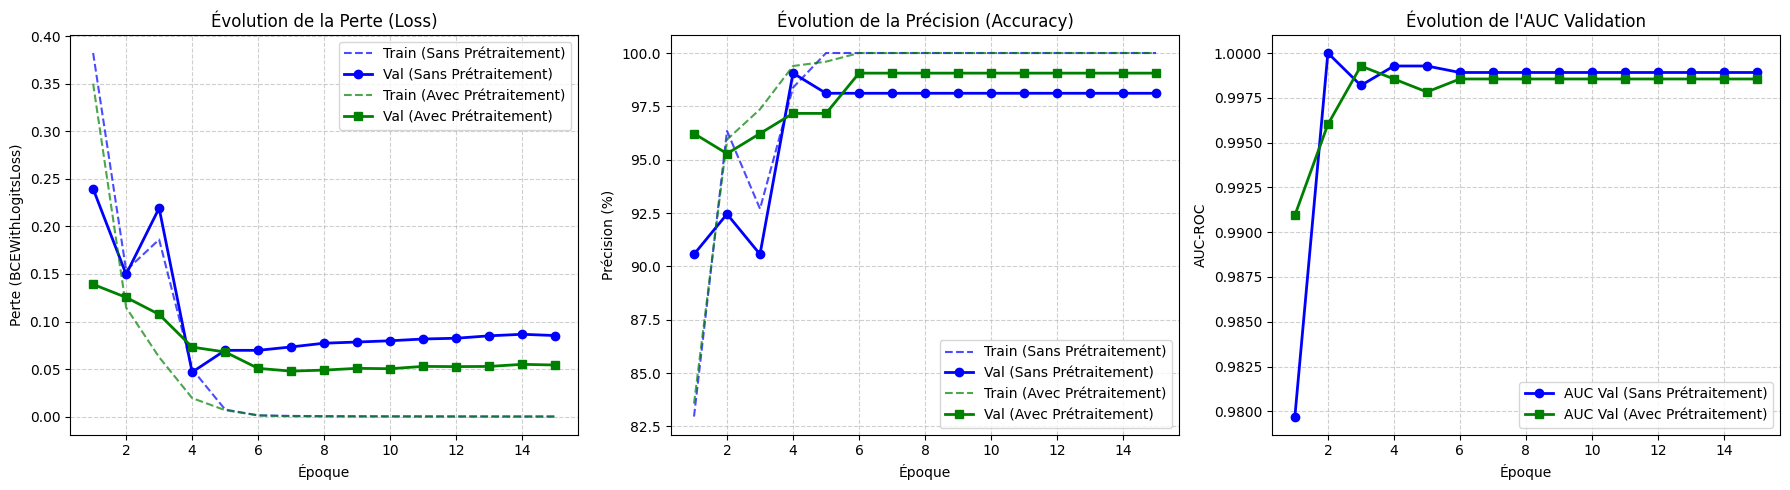

In [23]:
# Courbes d'Apprentissage Comparatives (Loss, Accuracy & AUC)
# Détermination dynamique du nombre d'époques
epochs = range(1, len(hist_rf_raw['train_loss']) + 1)

plt.figure(figsize=(18, 5))

#  Graphique de la Perte (Loss)
plt.subplot(1, 3, 1)
plt.plot(epochs, hist_rf_raw['train_loss'], 'b--', label='Train (Sans Prétraitement)', alpha=0.7)
plt.plot(epochs, hist_rf_raw['val_loss'], 'b-o', label='Val (Sans Prétraitement)', linewidth=2)
plt.plot(epochs, hist_rf_prep['train_loss'], 'g--', label='Train (Avec Prétraitement)', alpha=0.7)
plt.plot(epochs, hist_rf_prep['val_loss'], 'g-s', label='Val (Avec Prétraitement)', linewidth=2)
plt.title('Évolution de la Perte (Loss)')
plt.xlabel('Époque')
plt.ylabel('Perte (BCEWithLogitsLoss)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

#  Graphique de la Précision (Accuracy)
plt.subplot(1, 3, 2)
plt.plot(epochs, [acc * 100 for acc in hist_rf_raw['train_acc']], 'b--', label='Train (Sans Prétraitement)', alpha=0.7)
plt.plot(epochs, [acc * 100 for acc in hist_rf_raw['val_acc']], 'b-o', label='Val (Sans Prétraitement)', linewidth=2)
plt.plot(epochs, [acc * 100 for acc in hist_rf_prep['train_acc']], 'g--', label='Train (Avec Prétraitement)', alpha=0.7)
plt.plot(epochs, [acc * 100 for acc in hist_rf_prep['val_acc']], 'g-s', label='Val (Avec Prétraitement)', linewidth=2)
plt.title('Évolution de la Précision (Accuracy)')
plt.xlabel('Époque')
plt.ylabel('Précision (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

#  Graphique de l'AUC-ROC en Validation
plt.subplot(1, 3, 3)
plt.plot(epochs, hist_rf_raw['val_auc'], 'b-o', label='AUC Val (Sans Prétraitement)', linewidth=2)
plt.plot(epochs, hist_rf_prep['val_auc'], 'g-s', label='AUC Val (Avec Prétraitement)', linewidth=2)
plt.title('Évolution de l\'AUC Validation')
plt.xlabel('Époque')
plt.ylabel('AUC-ROC')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [24]:
# Évaluation
def evaluate_retfound(model, test_loader, name):
    model.eval()
    y_probs, y_true = [], []

    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs = imgs.to(DEVICE)
            outputs = model(imgs).squeeze(1)
            probs = torch.sigmoid(outputs).cpu().numpy()

            y_probs.extend(probs)
            y_true.extend(labels.numpy())

    y_probs = np.array(y_probs)
    y_true = np.array(y_true)
    y_pred = (y_probs >= 0.5).astype(int)

    acc = accuracy_score(y_true, y_pred)
    sens = recall_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_probs)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    spec = tn / (tn + fp)

    print(f"\n--- {name} ---")
    print(f"Accuracy                 : {acc:.4f}")
    print(f"Sensibilité (Recall)     : {sens:.4f}")
    print(f"Spécificité              : {spec:.4f}")
    print(f"Précision                : {prec:.4f}")
    print(f"F1-score                 : {f1:.4f}")
    print(f"ROC-AUC                  : {auc:.4f}")

    return {
        "name": name, "y_prob": y_probs, "y_pred": y_pred, "y_true": y_true,
        "acc": acc, "sens": sens, "spec": spec, "prec": prec, "f1": f1, "auc": auc
    }

res_rf_raw = evaluate_retfound(retfound_raw, test_loader_raw, "RETFound - Sans prétraitement")
res_rf_prep = evaluate_retfound(retfound_prep, test_loader_prep, "RETFound - Avec prétraitement")


--- RETFound - Sans prétraitement ---
Accuracy                 : 0.9623
Sensibilité (Recall)     : 0.9322
Spécificité              : 1.0000
Précision                : 1.0000
F1-score                 : 0.9649
ROC-AUC                  : 0.9910

--- RETFound - Avec prétraitement ---
Accuracy                 : 0.9623
Sensibilité (Recall)     : 0.9492
Spécificité              : 0.9787
Précision                : 0.9825
F1-score                 : 0.9655
ROC-AUC                  : 0.9982


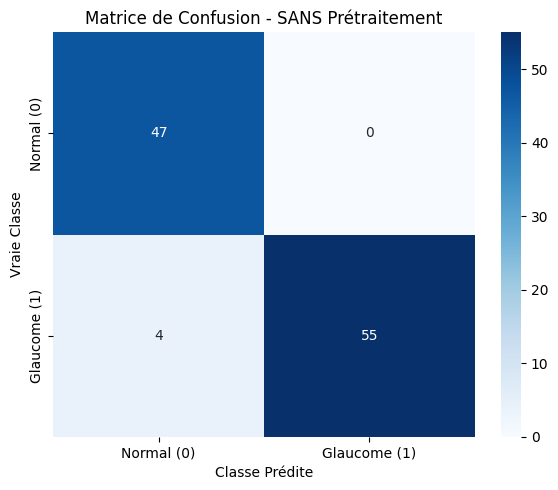

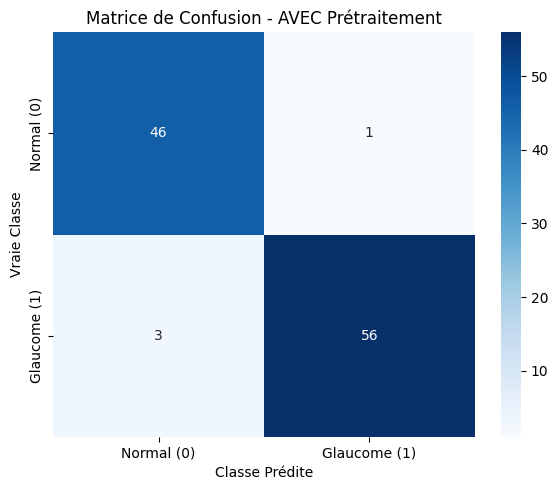

In [25]:
# Matrice de Confusion
def evaluate_and_plot_cm(
    model, test_loader, title="Modèle RETFound", class_names=["Normal (0)", "Glaucome (1)"]
):
  model.eval()
  all_targets = []
  all_probs = []

  # Extraction des prédictions sur le jeu de validation
  with torch.no_grad():
    for imgs, labels in test_loader:
      imgs = imgs.to(DEVICE)
      outputs = model(imgs).view(-1)
      probs = torch.sigmoid(outputs)

      all_probs.extend(probs.cpu().numpy())
      all_targets.extend(labels.numpy())

  # Conversion des probabilités en classes binaires (0 ou 1)
  all_preds = (np.array(all_probs) >= 0.5).astype(int)
  all_targets = np.array(all_targets).astype(int)

  # Calcul de la matrice de confusion
  cm = confusion_matrix(all_targets, all_preds)

  # Affichage graphique
  plt.figure(figsize=(6, 5))
  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      xticklabels=class_names,
      yticklabels=class_names,
  )
  plt.title(f"Matrice de Confusion - {title}")
  plt.ylabel("Vraie Classe")
  plt.xlabel("Classe Prédite")
  plt.tight_layout()
  plt.show()

  return all_targets, all_probs

# Évaluation des deux modèles (Sans vs Avec Prétraitement)
targets_raw, probs_raw = evaluate_and_plot_cm(
    retfound_raw, test_loader_raw, title="SANS Prétraitement"
)

targets_prep, probs_prep = evaluate_and_plot_cm(
    retfound_prep, test_loader_prep, title="AVEC Prétraitement"
)

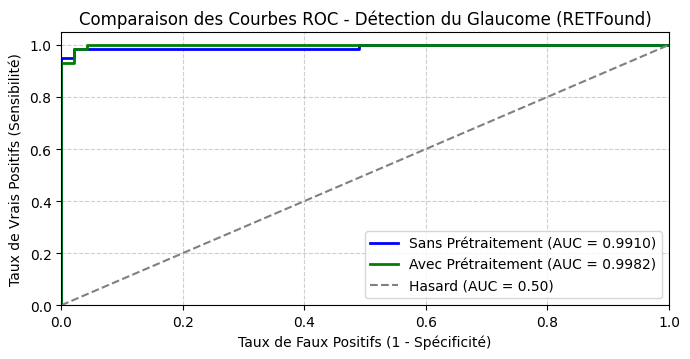


=================== TABLEAU COMPARATIF ===================
                     Pipeline  Accuracy  Sensibilité  Spécificité  Précision  F1-Score  ROC-AUC
RETFound - Sans prétraitement  0.962264     0.932203     1.000000   1.000000  0.964912 0.990984
RETFound - Avec prétraitement  0.962264     0.949153     0.978723   0.982456  0.965517 0.998197


In [36]:

from sklearn.metrics import auc, roc_curve

# Courbes ROC (Receiver Operating Characteristic) & AUC
plt.figure(figsize=(7, 3.7))

# Courbe ROC pour le modèle SANS prétraitement
fpr_raw, tpr_raw, _ = roc_curve(targets_raw, probs_raw)
auc_raw = auc(fpr_raw, tpr_raw)
plt.plot(
    fpr_raw,
    tpr_raw,
    color="blue",
    lw=2,
    label=f"Sans Prétraitement (AUC = {auc_raw:.4f})",
)

# Courbe ROC pour le modèle AVEC prétraitement
fpr_prep, tpr_prep, _ = roc_curve(targets_prep, probs_prep)
auc_prep = auc(fpr_prep, tpr_prep)
plt.plot(
    fpr_prep,
    tpr_prep,
    color="green",
    lw=2,
    label=f"Avec Prétraitement (AUC = {auc_prep:.4f})",
)

# Ligne de référence aléatoire
plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    lw=1.5,
    linestyle="--",
    label="Hasard (AUC = 0.50)",
)

# Configurations du graphique
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Taux de Faux Positifs (1 - Spécificité)")
plt.ylabel("Taux de Vrais Positifs (Sensibilité)")
plt.title("Comparaison des Courbes ROC - Détection du Glaucome (RETFound)")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# Tableau récapitulatif
results_df = pd.DataFrame([res_rf_raw, res_rf_prep])[
    ["name", "acc", "sens", "spec", "prec", "f1", "auc"]
]
results_df.columns = [
    "Pipeline",
    "Accuracy",
    "Sensibilité",
    "Spécificité",
    "Précision",
    "F1-Score",
    "ROC-AUC",
]

print("\n=================== TABLEAU COMPARATIF ===================")
print(results_df.to_string(index=False))

Veuillez uploader une image de fond d'œil (formats acceptés : PNG, JPG, JPEG)


Saving my_eye_image_1.jpeg to my_eye_image_1 (3).jpeg


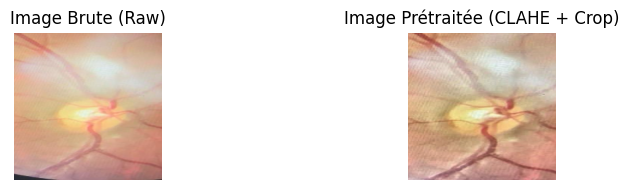


================ RÉSULTATS DES PRÉDICTIONS ================

--- RETFound - Sans Prétraitement ---
Probabilité de glaucome : 0.1765
Diagnostic prédit       : Sain

--- RETFound - Avec Prétraitement ---
Probabilité de glaucome : 0.0048
Diagnostic prédit       : Sain


In [31]:
#Test sur image externe
from google.colab import files

print("Veuillez uploader une image de fond d'œil (formats acceptés : PNG, JPG, JPEG)")
uploaded = files.upload()

if len(uploaded) > 0:
    image_name = list(uploaded.keys())[0]

    raw_img = load_raw(image_name)
    prep_img = load_preprocessed(image_name)

    fig, axes = plt.subplots(1, 2, figsize=(10, 2))
    axes[0].imshow(raw_img.astype(np.uint8))
    axes[0].set_title("Image Brute (Raw)")
    axes[0].axis("off")

    axes[1].imshow(prep_img.astype(np.uint8))
    axes[1].set_title("Image Prétraitée (CLAHE + Crop)")
    axes[1].axis("off")
    plt.tight_layout()
    plt.show()

    def predict_single_retfound(model, img_array, model_name):
        model.eval()
        tensor_img = transform_pipeline(img_array.astype(np.uint8)).unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            logit = model(tensor_img).squeeze(1)
            prob = torch.sigmoid(logit).item()

        pred_label = "Glaucome" if prob >= 0.5 else "Sain"

        print(f"\n--- {model_name} ---")
        print(f"Probabilité de glaucome : {prob:.4f}")
        print(f"Diagnostic prédit       : {pred_label}")
        return prob, pred_label

    print("\n================ RÉSULTATS DES PRÉDICTIONS ================")
    prob_raw, label_raw = predict_single_retfound(retfound_raw, raw_img, "RETFound - Sans Prétraitement")
    prob_prep, label_prep = predict_single_retfound(retfound_prep, prep_img, "RETFound - Avec Prétraitement")

else:
    print("Aucune image n'a été uploadée.")